In [1]:
import os
import sys
from pathlib import Path

# Let child processes find this Conda environment's numeric DLLs.
os.environ["PATH"] = str(Path(sys.prefix) / "Library" / "bin") + os.pathsep + os.environ["PATH"]
# Child processes only save images; no GUI backend is needed.
os.environ["MPLBACKEND"] = "Agg"

from concurrent.futures import ProcessPoolExecutor
import secrets
from nisp3_mini_mc_protocols import run_one_mc, set_temperature_schedule

In [2]:
K2K6_pairs = [
    (2.0, 0.0),
    (2.0, 1.0),
    (2.0, 2.0),
    (2.0, 3.0),
    (2.0, 4.0),
    (2.0, 5.0),
    (2.0, 6.0),
]

In [3]:
# lattice size
L = 30
Nx = round(1.7*L)
if Nx % 2 == 1:
    Nx += 1
Ny = L

In [4]:
# set uptemperatures
TK_init_list = [200, 175, 125]
TK_final_list = [175, 125, 1]
cooling_method_list = ["linear", "linear", "linear"]
cooling_rate_list = [5, 20, 25]

TK_list = set_temperature_schedule(
    TK_init_list, TK_final_list, cooling_method_list, cooling_rate_list,
)

In [5]:
meV_per_K = 0.08617333262
num_eq_sweeps = 15000
num_meas_sweeps = 5000
meas_per_every = 5
converg_per_every = 10

In [6]:
num_workers = max(len(K2K6_pairs), os.cpu_count() - 3)
with ProcessPoolExecutor(max_workers=num_workers) as pool:
    futures = [
        pool.submit(
            run_one_mc,
            Nx, Ny, K2, K6,
            secrets.randbits(128),
            TK_list,
            num_eq_sweeps, num_meas_sweeps,
            converg_per_every, meas_per_every,
        )
        for K2, K6 in K2K6_pairs
    ]

    folders = [future.result() for future in futures]

### Plot

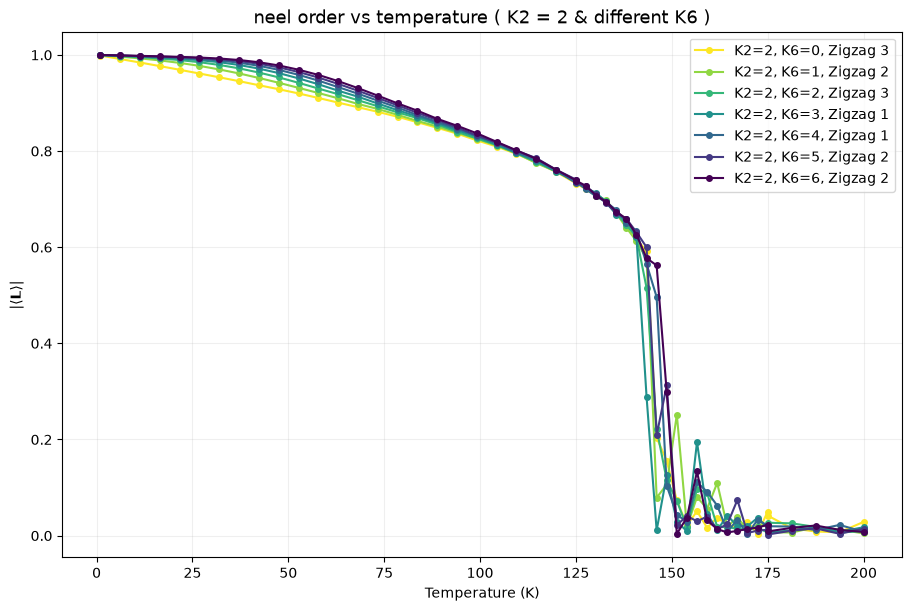

In [8]:
import json
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
from plotting_mc import plot_curves

%matplotlib inline

fig, ax = plt.subplots(figsize=(9, 6), constrained_layout=True)
colors = plt.cm.viridis(np.linspace(1, 0, len(folders)))

for folder, color in zip(folders, colors):
    folder = Path(folder)

    with (folder / "parameters.json").open(encoding="utf-8") as f:
        parameters = json.load(f)

    data = np.atleast_2d(np.loadtxt(
        folder / "data" / "neel_vs_temperature.csv",
        delimiter=",",
        skiprows=1,
    ))

    temperatures_K = data[:, 1]
    neel_data = data[:, 2:5]
    lowest_T_index = np.argmin(temperatures_K)
    zigzag_index = np.argmax(neel_data[lowest_T_index])

    plot_curves(
        temperatures_K,
        neel_data[:, zigzag_index],
        ax=ax,
        xlabel="Temperature (K)",
        ylabel1=r"$|\langle \mathbf{L}\rangle|$",
        label1=(
            f"K2={parameters['K2']:g}, K6={parameters['K6']:g}, "
            f"Zigzag {zigzag_index + 1}"
        ),
        colors=(color, "firebrick"),
        title=f"neel order vs temperature ( K2 = {parameters['K2']:g} & different K6 )",
    )

ax.legend()
plt.show()